# Đồ thị tính toán (Computational Graph) & Lan truyền ngược (Backpropagation)

Mạng Nơ-ron (Neural Networks) thực chất là những hàm toán học khổng lồ với hàng triệu tham số. Việc tính đạo hàm bằng tay cho chúng là bất khả thi. **Đồ thị tính toán** và thuật toán **Lan truyền ngược** ra đời để tự động hóa hoàn toàn quá trình này.

**1. Đồ thị tính toán (Hành trình Forward Pass):**
Mọi phương trình toán học phức tạp đều có thể được bẻ gãy thành các phép toán nguyên thủy cơ bản (cộng, nhân, hàm kích hoạt).
 
Ví dụ: $f(x, y) = \text{ReLU}(x \cdot y + x)$.
Ta biểu diễn nó thành một đồ thị có hướng: 
- Node lá là $x, y$. 
- Đi qua node nhân: $a = x \cdot y$. 
- Đi qua node cộng: $b = a + x$. 
- Đi qua node kích hoạt: $out = \text{ReLU}(b)$.

**2. Lan truyền ngược (Hành trình Backward Pass):**
Để biết $x$ và $y$ ảnh hưởng thế nào đến $out$ (tức là tính đạo hàm $\frac{\partial out}{\partial x}$ và $\frac{\partial out}{\partial y}$), ta áp dụng **Quy tắc chuỗi (Chain Rule)** từ giải tích, đi ngược từ $out$ về các node lá:
$$\frac{\partial out}{\partial x} = \frac{\partial out}{\partial b} \cdot \frac{\partial b}{\partial a} \cdot \frac{\partial a}{\partial x}$$
Mỗi node chỉ cần biết đúng 2 thứ: Đạo hàm cục bộ của chính nó (Local Gradient) và Đạo hàm từ node phía sau truyền tới (Upstream Gradient). Nhân chúng lại với nhau, ta có Downstream Gradient để truyền tiếp về trước.

In [1]:
import math

class Value:
    """Động cơ đạo hàm tự động (Autograd engine) theo kiến trúc Đồ thị tính toán."""
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0 # Lưu trữ đạo hàm (gradient)
        self._backward = lambda: None # Hàm lan truyền ngược cục bộ của node này
        self._prev = set(_children) # Các node cha tạo ra node này
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad}, label={self.label})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        # Local gradient của phép CỘNG: f(x, y) = x + y => df/dx = 1, df/dy = 1
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        # Local gradient của phép NHÂN: f(x, y) = x * y => df/dx = y, df/dy = x
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        # Local gradient của ReLU: df/dx = 1 nếu x > 0 ngược lại = 0
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # Sắp xếp Topo (Topological Sort) để đảm bảo duyệt từ Output ngược về Input
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # Đạo hàm của node cuối cùng đối với chính nó luôn bằng 1
        self.grad = 1.0
        # Chạy ngược đồ thị
        for node in reversed(topo):
            node._backward()

In [2]:
# 1. Khởi tạo các Node đầu vào (Lá)
x = Value(-2.0, label='x')
y = Value(5.0, label='y')
z = Value(-4.0, label='z')

# 2. Xây dựng đồ thị tính toán (Forward pass)
# Phương trình: L = ReLU((x * y) + z)
q = x * y; q.label = 'q'
p = q + z; p.label = 'p'
L = p.relu(); L.label = 'L'

print("--- Kết quả tính toán xuôi (Forward Pass) ---")
print(f"q = x * y = {q.data}")
print(f"p = q + z = {p.data}")
print(f"L = ReLU(p) = {L.data}")

# 3. Kích hoạt Lan truyền ngược (Backward pass)
L.backward()

print("\n--- Kết quả Đạo hàm tự động (Backward Pass) ---")
print(f"dL/dL = {L.grad} (Đạo hàm của Output với chính nó luôn là 1)")
print(f"dL/dp = {p.grad} (Đi qua ReLU: p = -14 < 0 nên gradient bị chặn = 0)")
print(f"dL/dq = {q.grad} (Vì p = q + z, dL/dq = dL/dp * 1 = 0)")
print(f"dL/dx = {x.grad} (Vì q = x * y, dL/dx = dL/dq * y = 0 * 5 = 0)")
print(f"dL/dy = {y.grad} (Vì q = x * y, dL/dy = dL/dq * x = 0 * -2 = 0)")

# 4. Thử nghiệm một nhánh khác để thấy Gradient chảy qua ReLU
print("\n--- Thử nghiệm với giá trị x dương để Gradient đi qua ReLU ---")
x2 = Value(2.0, label='x2')
y2 = Value(5.0, label='y2')
z2 = Value(-4.0, label='z2')
L2 = (x2 * y2 + z2).relu()
L2.label = 'L2'

L2.backward()
print(f"Output L2 = {L2.data}")
print(f"dL2/dx2 = {x2.grad} (Quy tắc chuỗi: dL/dp * dp/dq * dq/dx = 1 * 1 * y2 = 5)")
print(f"dL2/dy2 = {y2.grad} (Quy tắc chuỗi: 1 * 1 * x2 = 2)")

--- Kết quả tính toán xuôi (Forward Pass) ---
q = x * y = -10.0
p = q + z = -14.0
L = ReLU(p) = 0

--- Kết quả Đạo hàm tự động (Backward Pass) ---
dL/dL = 1.0 (Đạo hàm của Output với chính nó luôn là 1)
dL/dp = 0.0 (Đi qua ReLU: p = -14 < 0 nên gradient bị chặn = 0)
dL/dq = 0.0 (Vì p = q + z, dL/dq = dL/dp * 1 = 0)
dL/dx = 0.0 (Vì q = x * y, dL/dx = dL/dq * y = 0 * 5 = 0)
dL/dy = 0.0 (Vì q = x * y, dL/dy = dL/dq * x = 0 * -2 = 0)

--- Thử nghiệm với giá trị x dương để Gradient đi qua ReLU ---
Output L2 = 6.0
dL2/dx2 = 5.0 (Quy tắc chuỗi: dL/dp * dp/dq * dq/dx = 1 * 1 * y2 = 5)
dL2/dy2 = 2.0 (Quy tắc chuỗi: 1 * 1 * x2 = 2)


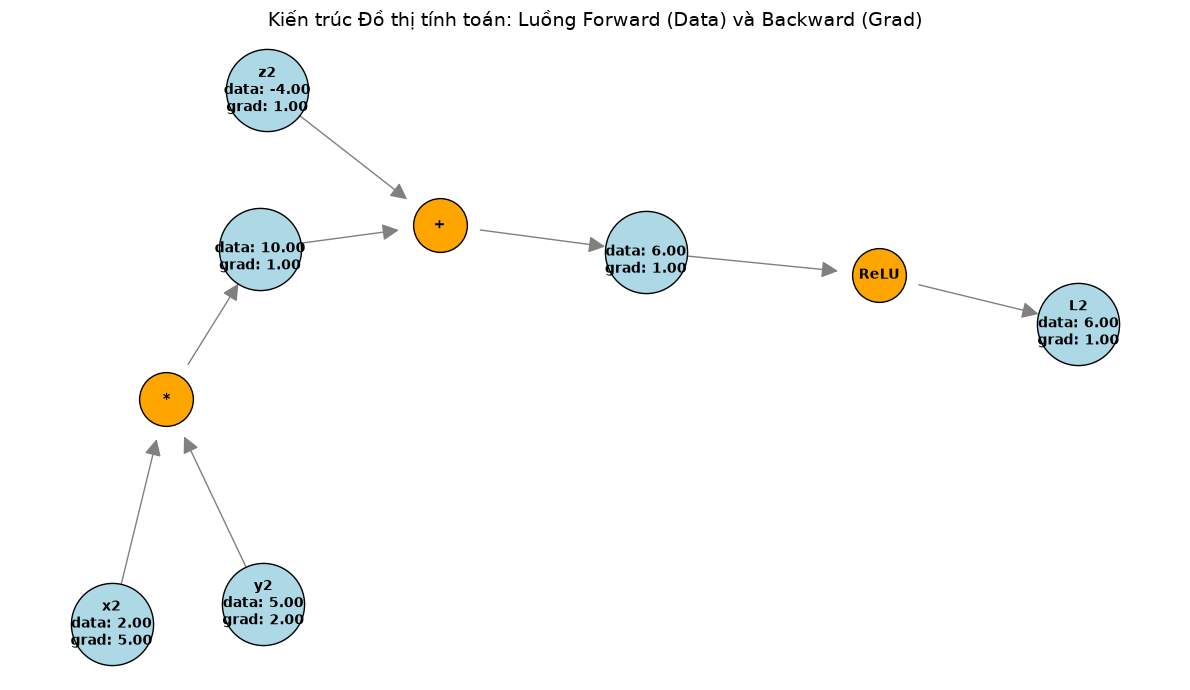

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_computational_graph(root):
    # 1. Đệ quy ngược từ Output để thu thập toàn bộ Node (Biến) và Edge (Kết nối)
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)

    # 2. Xây dựng đồ thị có hướng (DiGraph)
    G = nx.DiGraph()
    
    for n in nodes:
        uid = str(id(n))
        # Khai báo Node biến số (Values)
        G.add_node(uid, label=f"{n.label}\ndata: {n.data:.2f}\ngrad: {n.grad:.2f}", type='var')
        
        if n._op:
            # Khai báo Node phép toán (Operations)
            op_uid = uid + '_op'
            G.add_node(op_uid, label=n._op, type='op')
            G.add_edge(op_uid, uid) # Nối Operation tới Biến kết quả

    # Nối các Biến đầu vào tới Operation tương ứng
    for n1, n2 in edges:
        G.add_edge(str(id(n1)), str(id(n2)) + '_op')

    # 3. Thiết lập thông số vẽ Matplotlib
    plt.figure(figsize=(12, 7))
    # Dùng thuật toán vật lý lò xo (spring layout) để dàn đều các node
    pos = nx.spring_layout(G, seed=42) 
    
    # Phân loại màu sắc để dễ nhìn (Biến: Xanh, Phép toán: Cam)
    var_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'var']
    op_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'op']
    
    nx.draw_networkx_nodes(G, pos, nodelist=var_nodes, node_color='lightblue', node_size=3500, edgecolors='black')
    nx.draw_networkx_nodes(G, pos, nodelist=op_nodes, node_color='orange', node_size=1500, edgecolors='black')
    nx.draw_networkx_edges(G, pos, arrowsize=25, edge_color='gray', node_size=3500)
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, 'label'), font_size=10, font_weight='bold')

    plt.title("Kiến trúc Đồ thị tính toán: Luồng Forward (Data) và Backward (Grad)", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Trực quan hóa nhánh L2 (Nhánh có Gradient = 5.0 đi qua ReLU)
draw_computational_graph(L2)

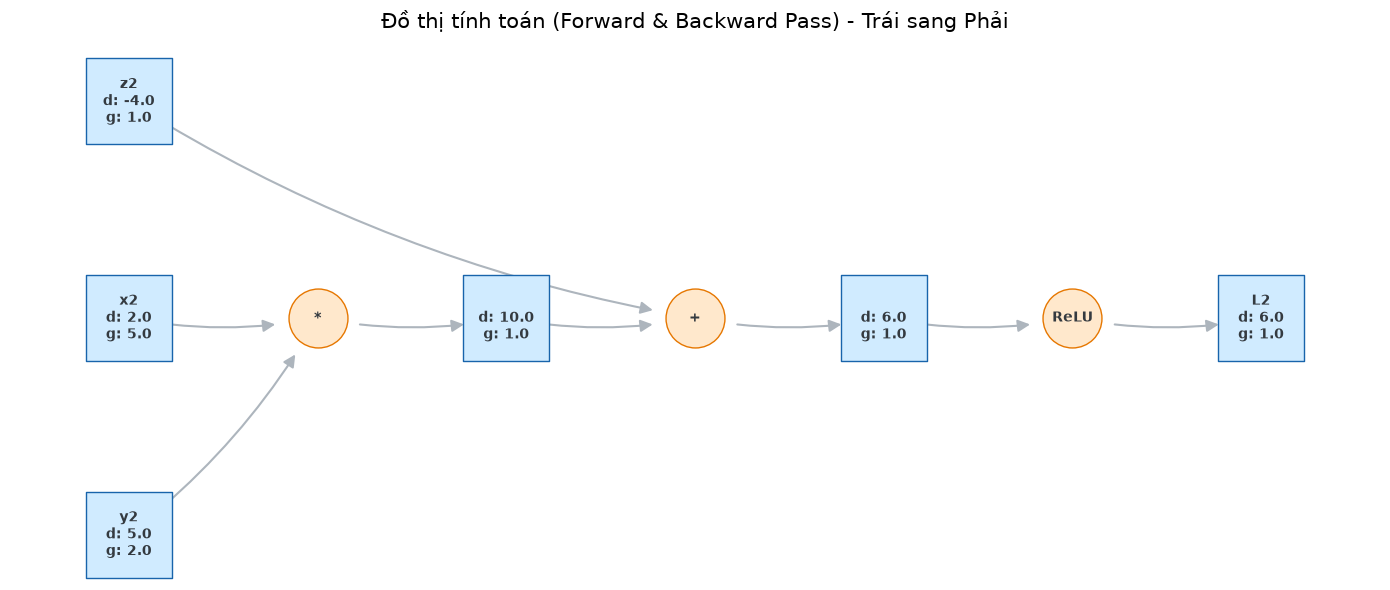

In [4]:
# Đồ thị dùng spring_layout nhằm mô phỏng lò xo trong vậy lý
# Nên trực quan hóa lại đồ thị tính toán mang dáng dấp của PyTorch & TensorFlow -> viết Hierarchical Layout bằng Topological Sort

import networkx as nx
import matplotlib.pyplot as plt

def draw_computational_graph_beautiful(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)

    G = nx.DiGraph()
    for n in nodes:
        uid = str(id(n))
        # Định dạng text hiển thị gọn gàng hơn
        G.add_node(uid, label=f"{n.label}\nd: {n.data:.1f}\ng: {n.grad:.1f}", type='var')
        if n._op:
            op_uid = uid + '_op'
            G.add_node(op_uid, label=n._op, type='op')
            G.add_edge(op_uid, uid)
    for n1, n2 in edges:
        G.add_edge(str(id(n1)), str(id(n2)) + '_op')

    # --- Thuật toán dàn trang phân tầng (Từ Trái sang Phải) ---
    layer_map = {}
    for node in nx.topological_sort(G):
        ancestors = list(G.predecessors(node))
        # Nút lá nằm ở layer 0, các nút tiếp theo cộng dồn độ sâu
        layer_map[node] = 0 if not ancestors else max(layer_map[a] for a in ancestors) + 1
        
    layer_counts = {}
    for layer in layer_map.values():
        layer_counts[layer] = layer_counts.get(layer, 0) + 1
        
    current_y = {layer: (layer_counts[layer] - 1) / 2.0 for layer in layer_counts}
    pos = {}
    for node in G.nodes():
        layer = layer_map[node]
        # X dàn theo layer, Y trải đều từ trên xuống
        pos[node] = (layer * 2, current_y[layer]) 
        current_y[layer] -= 1

    # --- Thiết lập đồ họa ---
    plt.figure(figsize=(14, 6))
    
    var_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'var']
    op_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'op']
    
    # Biến số (Màu xanh dương nhạt, hình chữ nhật)
    nx.draw_networkx_nodes(G, pos, nodelist=var_nodes, node_color='#d0ebff', 
                           node_size=3800, edgecolors='#1864ab', node_shape='s')
    # Phép toán (Màu cam nhạt, hình tròn)
    nx.draw_networkx_nodes(G, pos, nodelist=op_nodes, node_color='#ffe8cc', 
                           node_size=1800, edgecolors='#e67700', node_shape='o')
    
    # Đường viền mũi tên cong nhẹ
    nx.draw_networkx_edges(G, pos, arrowsize=18, edge_color='#adb5bd', 
                           width=1.5, node_size=3800, connectionstyle="arc3,rad=0.1")
    
    # Chữ
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, 'label'), 
                            font_size=10, font_weight='bold', font_color='#343a40')

    plt.title("Đồ thị tính toán (Forward & Backward Pass) - Trái sang Phải", fontsize=15, pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Trực quan hóa nhánh L2
draw_computational_graph_beautiful(L2)

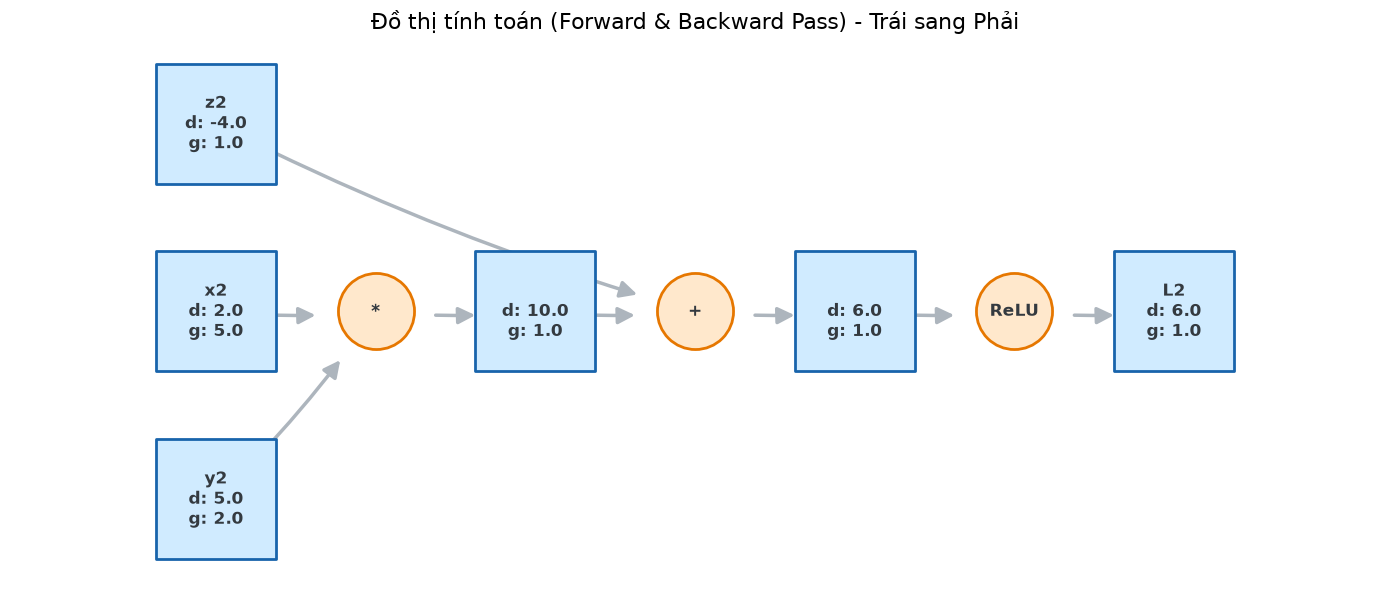

In [7]:
# Cải thiện cho dễ nhìn và trực quan hơn

import networkx as nx
import matplotlib.pyplot as plt

def draw_computational_graph_massive(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)

    G = nx.DiGraph()
    for n in nodes:
        uid = str(id(n))
        G.add_node(uid, label=f"{n.label}\nd: {n.data:.1f}\ng: {n.grad:.1f}", type='var')
        if n._op:
            op_uid = uid + '_op'
            G.add_node(op_uid, label=n._op, type='op')
            G.add_edge(op_uid, uid)
    for n1, n2 in edges:
        G.add_edge(str(id(n1)), str(id(n2)) + '_op')

    layer_map = {}
    for node in nx.topological_sort(G):
        ancestors = list(G.predecessors(node))
        layer_map[node] = 0 if not ancestors else max(layer_map[a] for a in ancestors) + 1
        
    layer_counts = {}
    for layer in layer_map.values():
        layer_counts[layer] = layer_counts.get(layer, 0) + 1
        
    current_y = {layer: (layer_counts[layer] - 1) / 2.0 for layer in layer_counts}
    pos = {}
    for node in G.nodes():
        layer = layer_map[node]
        # Ép khoảng cách trục X gần lại (hệ số 1.2 thay vì 2.0) để tạo sự liền mạch
        pos[node] = (layer * 1.2, current_y[layer]) 
        current_y[layer] -= 1

    plt.figure(figsize=(14, 6))
    ax = plt.gca()
    ax.margins(0.15) # Căn lề vừa đủ để các node khổng lồ không bị cắt viền
    
    var_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'var']
    op_nodes = [node for node, attr in G.nodes(data=True) if attr.get('type') == 'op']
    
    # Tăng mạnh node_size và làm đậm viền (linewidths)
    nx.draw_networkx_nodes(G, pos, nodelist=var_nodes, node_color='#d0ebff', 
                           node_size=7500, edgecolors='#1864ab', node_shape='s', linewidths=2)
    nx.draw_networkx_nodes(G, pos, nodelist=op_nodes, node_color='#ffe8cc', 
                           node_size=3000, edgecolors='#e67700', node_shape='o', linewidths=2)
    
    # Mũi tên to hơn, nét nối dày hơn và bớt độ cong (rad=0.05)
    nx.draw_networkx_edges(G, pos, arrowsize=25, edge_color='#adb5bd', 
                           width=2.5, node_size=7500, connectionstyle="arc3,rad=0.05")
    
    # Tăng font size
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, 'label'), 
                            font_size=12, font_weight='bold', font_color='#343a40')

    plt.title("Đồ thị tính toán (Forward & Backward Pass) - Trái sang Phải", fontsize=16, pad=10)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Kích hoạt vẽ lại nhánh L2
draw_computational_graph_massive(L2)